# 04 - Multi-Borough Comparative Analysis & Target Borough Selection

**Title**: `04_borough_selection.ipynb`  
**Purpose**: Evaluate complaint group volumes, meteorological precipitation correlations, storm sensitivity, and data quality across all five NYC boroughs to establish empirical evidence for borough selection.  
**Inputs**: `data/processed/complaints_window_all.csv.gz`, `data/processed/flood_vs_rain_all_boroughs.csv`, `data/processed/report_tables/t1_borough_summary.csv`, `t2_correlations_all_days.csv`, `t4_robust_correlations.csv`, `t5_storm_days.csv`, `t7_evidence_summary.csv`  
**Outputs**: Borough volume summary (T1), correlation profiles (T2), spike days (T3), robust correlations (T4), storm days (T5), Brooklyn deep dive (T6), evidence summary (T7), bootstrap confidence intervals, scatter panels and CI plots.  
**Runtime**: ~15-25 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker, md
RUN_HEAVY = False
RUN_API = False

In [2]:
import pandas as pd
import numpy as np
from src.preprocessing.borough_analysis import load_and_prepare_daily_data, BOROUGH_ORDER
from src.preprocessing.borough_check import (
    compute_t1, compute_t2, compute_t3, compute_t4, compute_t5, compute_t6, compute_t7
)

complaints_path = ROOT / "data" / "processed" / "complaints_window_all.csv.gz"
flood_rain_path = ROOT / "data" / "processed" / "flood_vs_rain_all_boroughs.csv"

print(f"Loading data from {complaints_path.relative_to(ROOT)} and {flood_rain_path.relative_to(ROOT)}...")
df_raw = pd.read_csv(
    complaints_path,
    dtype={"unique_key": str, "resolution_id": str, "incident_address": str},
    keep_default_na=False,
)
df_raw["created_dt"] = pd.to_datetime(df_raw["created_date"], errors="coerce")
df_raw["date"] = df_raw["created_dt"].dt.strftime("%Y-%m-%d")

daily_df = load_and_prepare_daily_data(flood_rain_path)
print(f"Loaded {len(df_raw):,} extract records and {len(daily_df):,} daily records across 5 boroughs.")

Loading data from data\processed\complaints_window_all.csv.gz and data\processed\flood_vs_rain_all_boroughs.csv...


Loaded 874,893 extract records and 1,825 daily records across 5 boroughs.


In [3]:
t1_df = compute_t1(daily_df, df_raw)
t1_saved = pd.read_csv(ROOT / "data" / "processed" / "report_tables" / "t1_borough_summary.csv")

t1_df["borough"] = pd.Categorical(t1_df["borough"], categories=BOROUGH_ORDER, ordered=True)
t1_df = t1_df.sort_values("borough").reset_index(drop=True)

print("=== Table T1: Borough Summary Metrics ===")
print(t1_df.to_string(index=False))

diff_t1 = int((t1_df.drop(columns=["borough"]) != t1_saved.drop(columns=["borough"])).sum().sum())
print(f"\nDiscrepancies vs saved t1_borough_summary.csv: {diff_t1}")

=== Table T1: Borough Summary Metrics ===
      borough  flood_total  road_total  noise_total  sewer_backup_total  days_flood_ge_1  median_daily_flood  max_daily_flood  p95_daily_flood
     BROOKLYN         5520       16138       211843                3006              360                10.0              228             43.6
       QUEENS         6787       25037       159288                4557              363                11.0              243             53.8
        BRONX         1127        6486       218731                 884              293                 2.0               29              9.8
    MANHATTAN         1165        8271       179159                 452              307                 2.0               31             10.0
STATEN ISLAND         1449        5215        18887                 891              322                 3.0               79             11.8

Discrepancies vs saved t1_borough_summary.csv: 0


In [4]:
t2_df = compute_t2(daily_df)
t2_saved = pd.read_csv(ROOT / "data" / "processed" / "report_tables" / "t2_correlations_all_days.csv")

t2_df["borough"] = pd.Categorical(t2_df["borough"], categories=BOROUGH_ORDER, ordered=True)
t2_df = t2_df.sort_values("borough").reset_index(drop=True)

print("=== Table T2: Correlations on All 365 Calendar Days ===")
print(t2_df.to_string(index=False))

diff_t2 = int((t2_df.drop(columns=["borough"]) != t2_saved.drop(columns=["borough"])).sum().sum())
print(f"\nDiscrepancies vs saved t2_correlations_all_days.csv: {diff_t2}")

=== Table T2: Correlations on All 365 Calendar Days ===


      borough  pearson_same_day  spearman_same_day  pearson_prev_day  spearman_prev_day  pearson_3d_sum  spearman_3d_sum
     BROOKLYN            0.5614             0.3422            0.2293             0.2456          0.4699           0.4220
       QUEENS            0.4902             0.2890            0.2084             0.2254          0.4095           0.3730
        BRONX            0.5055             0.2584            0.1749             0.1143          0.4140           0.2848
    MANHATTAN            0.5399             0.2973            0.1944             0.2438          0.4298           0.3985
STATEN ISLAND            0.4207             0.2358            0.1204             0.2104          0.3175           0.3024

Discrepancies vs saved t2_correlations_all_days.csv: 0


In [5]:
from src.preprocessing.borough_analysis import compute_bootstrap_ci, check_ci_overlap

ci_df = compute_bootstrap_ci(daily_df, boroughs=BOROUGH_ORDER, n_resamples=2000, seed=0)
print("=== 95% Bootstrap Confidence Intervals for Spearman Correlation (3-Day Rain Sum) ===")
print(ci_df.to_string(index=False))

bk_ci = (
    float(ci_df.loc[ci_df["borough"] == "BROOKLYN", "ci_lower_95"].values[0]),
    float(ci_df.loc[ci_df["borough"] == "BROOKLYN", "ci_upper_95"].values[0])
)
qn_ci = (
    float(ci_df.loc[ci_df["borough"] == "QUEENS", "ci_lower_95"].values[0]),
    float(ci_df.loc[ci_df["borough"] == "QUEENS", "ci_upper_95"].values[0])
)

ci_overlaps = check_ci_overlap(bk_ci, qn_ci)
overlap_word = "overlap" if ci_overlaps else "do not overlap"
ci_sentence = (
    f"The 95% bootstrap confidence intervals of the Spearman 3-day precipitation correlation "
    f"for Brooklyn ([{bk_ci[0]:.4f}, {bk_ci[1]:.4f}]) and Queens ([{qn_ci[0]:.4f}, {qn_ci[1]:.4f}]) {overlap_word}."
)
print(f"\nBootstrap CI Comparison:\n{ci_sentence}")

=== 95% Bootstrap Confidence Intervals for Spearman Correlation (3-Day Rain Sum) ===
      borough  spearman_3d_sum  ci_lower_95  ci_upper_95  margin_error
     BROOKLYN         0.421988     0.328354     0.514217      0.092932
       QUEENS         0.373037     0.277119     0.463762      0.093321
        BRONX         0.284801     0.182608     0.377716      0.097554
    MANHATTAN         0.398499     0.306264     0.481997      0.087866
STATEN ISLAND         0.302407     0.204575     0.395617      0.095521

Bootstrap CI Comparison:
The 95% bootstrap confidence intervals of the Spearman 3-day precipitation correlation for Brooklyn ([0.3284, 0.5142]) and Queens ([0.2771, 0.4638]) overlap.


In [6]:
t3_df = compute_t3(daily_df)
t4_df = compute_t4(daily_df, t3_df)
t4_saved = pd.read_csv(ROOT / "data" / "processed" / "report_tables" / "t4_robust_correlations.csv")

t4_df["borough"] = pd.Categorical(t4_df["borough"], categories=BOROUGH_ORDER, ordered=True)
t4_df = t4_df.sort_values("borough").reset_index(drop=True)

print("=== Table T3: Top-10 Flood Spike Days per Borough (First 15 Rows) ===")
print(t3_df.head(15).to_string(index=False))

print("\n=== Table T4: Robust Correlations (Excluding Dry Spike Days) ===")
print(t4_df.to_string(index=False))

diff_t4 = int((t4_df.drop(columns=["borough"]) != t4_saved.drop(columns=["borough"])).sum().sum())
print(f"\nDiscrepancies vs saved t4_robust_correlations.csv: {diff_t4}")

=== Table T3: Top-10 Flood Spike Days per Borough (First 15 Rows) ===


 borough  rank       date  flood_count  rain_mm  rain_3d_sum  spike_no_rain
BROOKLYN     1 2026-07-06          228     49.6         70.7          False
BROOKLYN     2 2026-05-21          148      7.2         15.9           True
BROOKLYN     3 2026-05-20          145      7.2          8.7           True
BROOKLYN     4 2026-05-24          129     40.7         52.7          False
BROOKLYN     5 2026-07-18          105     38.9         39.9          False
BROOKLYN     6 2026-08-03           97     29.9         39.0          False
BROOKLYN     7 2025-12-19           90     26.1         26.1          False
BROOKLYN     8 2026-08-20           87     46.9         60.3          False
BROOKLYN     9 2026-03-05           79     16.6         27.9          False
BROOKLYN    10 2026-08-23           76      9.3         10.9           True
  QUEENS     1 2026-05-21          243      8.6         14.7           True
  QUEENS     2 2026-07-18          211     37.7         38.2          False
  QUEENS   

In [7]:
t5_df = compute_t5(daily_df)
t5_saved = pd.read_csv(ROOT / "data" / "processed" / "report_tables" / "t5_storm_days.csv")

t5_df["borough"] = pd.Categorical(t5_df["borough"], categories=BOROUGH_ORDER, ordered=True)
t5_df = t5_df.sort_values("borough").reset_index(drop=True)

print("=== Table T5: Storm Days Analysis (Rain >= 20 mm) ===")
print(t5_df.to_string(index=False))

diff_t5 = int((t5_df.drop(columns=["borough"]) != t5_saved.drop(columns=["borough"])).sum().sum())
print(f"\nDiscrepancies vs saved t5_storm_days.csv: {diff_t5}")

t7_df = compute_t7(t1_df, t4_df, t5_df)
t7_saved = pd.read_csv(ROOT / "data" / "processed" / "report_tables" / "t7_evidence_summary.csv")

print("\n=== Table T7: Comparative Evidence Summary (Ranked by Weakest Group Size) ===")
print(t7_df.to_string(index=False))

diff_t7 = int((t7_df.drop(columns=["borough"]) != t7_saved.drop(columns=["borough"])).sum().sum())
print(f"\nDiscrepancies vs saved t7_evidence_summary.csv: {diff_t7}")

=== Table T5: Storm Days Analysis (Rain >= 20 mm) ===
      borough  storm_days_count  non_storm_days_count  mean_flood_storm  median_flood_storm  mean_flood_non_storm  median_flood_non_storm  mean_ratio
     BROOKLYN                19                   346             57.63                39.0                 12.79                     9.0        4.51
       QUEENS                18                   347             66.33                47.5                 16.12                    11.0        4.12
        BRONX                17                   348             10.94                11.0                  2.70                     2.0        4.05
    MANHATTAN                17                   348             11.06                 9.0                  2.81                     2.0        3.94
STATEN ISLAND                16                   349             17.25                14.0                  3.36                     2.0        5.13

Discrepancies vs saved t5_storm_days.csv: 0



In [8]:
t6_df, t6_details = compute_t6(df_raw, daily_df)
print("=== Table T6: Brooklyn Deep Dive Summary ===")
print(t6_df.to_string(index=False))

target_deep_dive_dates = ["2026-05-20", "2026-05-21", "2026-07-06"]
for d in target_deep_dive_dates:
    det = t6_details[d]
    print(f"\n--- Detailed Breakdown for {d} ---")
    print("Top Complaint Types & Descriptors:")
    print(det["type_desc"].head(5).to_string(index=False))
    print("\nHourly Flood Distribution:")
    print(det["hours"].to_string())
    print("\nTop 5 Incident Addresses:")
    print(det["top5_addresses"].to_string())

d20_h19_count = int(t6_details["2026-05-20"]["hours"].get(19, 0))
print(f"\nVerified 2026-05-20 Hour 19 flood count: {d20_h19_count}")

=== Table T6: Brooklyn Deep Dive Summary ===
      date  flood_count  rain_day_t_mm  rain_t_minus_1_mm  rain_t_minus_2_mm  rain_t_minus_3_mm  rain_3d_sum_mm  distinct_addresses top1_address  top1_address_count  top1_address_share_pct        top_named_address  top_named_address_count  top_named_address_share_pct
2026-05-20          145            7.2                1.5                0.0                0.0             8.7                 100           ''                  34                   23.45 443 KNICKERBOCKER AVENUE                        7                         4.83
2026-05-21          148            7.2                7.2                1.5                0.0            15.9                 108           ''                  36                   24.32          578 TROY AVENUE                        2                         1.35
2026-07-06          228           49.6               13.6                7.5                0.5            70.7                 162           ''       

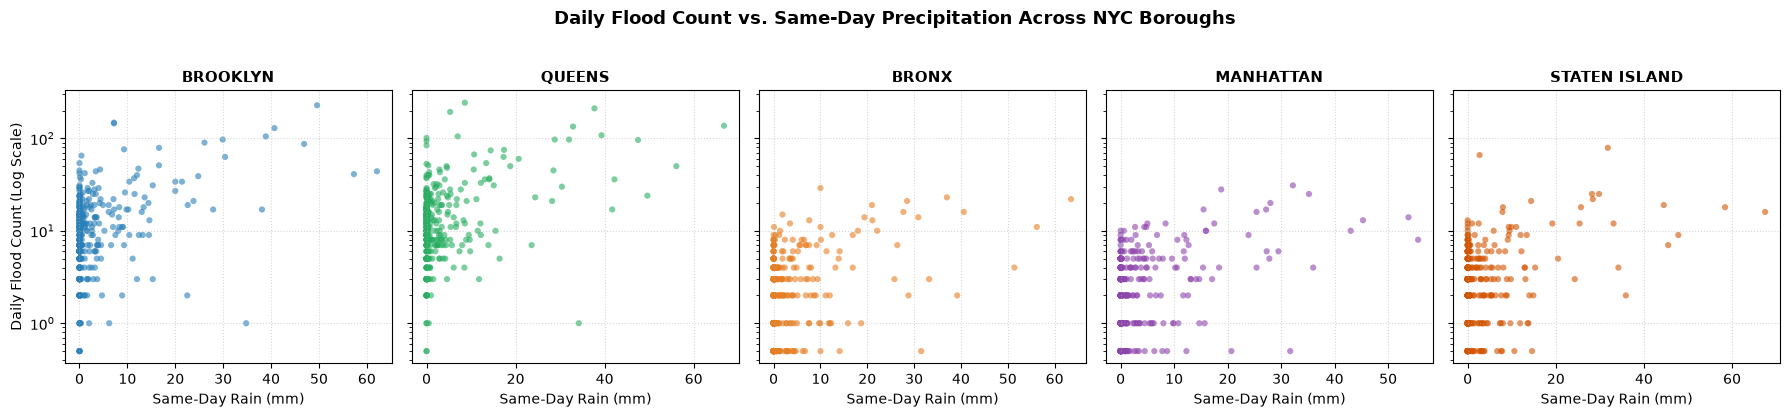

Saved figure: report\figures\04_flood_vs_rain_scatter.png


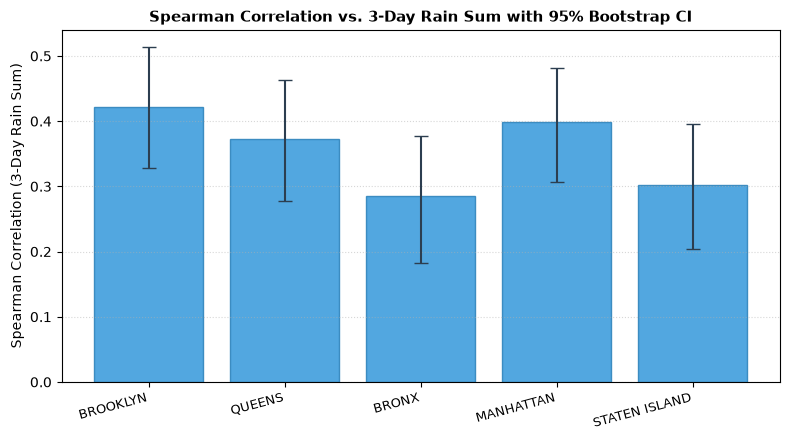

Saved figure: report\figures\04_spearman_3d_bootstrap_ci.png


In [9]:
from src.preprocessing.borough_analysis import plot_borough_flood_vs_rain, plot_spearman_ci

fig1_path = ROOT / "report" / "figures" / "04_flood_vs_rain_scatter.png"
plot_borough_flood_vs_rain(daily_df, fig1_path)
print(f"Saved figure: {fig1_path.relative_to(ROOT)}")

fig2_path = ROOT / "report" / "figures" / "04_spearman_3d_bootstrap_ci.png"
plot_spearman_ci(ci_df, fig2_path)
print(f"Saved figure: {fig2_path.relative_to(ROOT)}")

In [10]:
flood_by_borough = [int(t1_df[t1_df["borough"] == b]["flood_total"].values[0]) for b in BOROUGH_ORDER]
road_by_borough = [int(t1_df[t1_df["borough"] == b]["road_total"].values[0]) for b in BOROUGH_ORDER]
noise_by_borough = [int(t1_df[t1_df["borough"] == b]["noise_total"].values[0]) for b in BOROUGH_ORDER]
sewer_by_borough = [int(t1_df[t1_df["borough"] == b]["sewer_backup_total"].values[0]) for b in BOROUGH_ORDER]

pearson_same_day = [round(float(t2_df[t2_df["borough"] == b]["pearson_same_day"].values[0]), 4) for b in BOROUGH_ORDER]
pearson_3d = [round(float(t2_df[t2_df["borough"] == b]["pearson_3d_sum"].values[0]), 4) for b in BOROUGH_ORDER]
spearman_3d = [round(float(t2_df[t2_df["borough"] == b]["spearman_3d_sum"].values[0]), 4) for b in BOROUGH_ORDER]

storm_counts = [int(t5_df[t5_df["borough"] == b]["storm_days_count"].values[0]) for b in BOROUGH_ORDER]

max_flood_bk = int(t1_df[t1_df["borough"] == "BROOKLYN"]["max_daily_flood"].values[0])
max_flood_qn = int(t1_df[t1_df["borough"] == "QUEENS"]["max_daily_flood"].values[0])

deep_dive_counts = [int(t6_df[t6_df["date"] == d]["flood_count"].values[0]) for d in target_deep_dive_dates]
hour_19_cnt = int(t6_details["2026-05-20"]["hours"].get(19, 0))

checker = Checker()
checker.check("totals flood [5520, 6787, 1127, 1165, 1449]", flood_by_borough, [5520, 6787, 1127, 1165, 1449])
checker.check("totals road [16138, 25037, 6486, 8271, 5215]", road_by_borough, [16138, 25037, 6486, 8271, 5215])
checker.check("totals noise [211843, 159288, 218731, 179159, 18887]", noise_by_borough, [211843, 159288, 218731, 179159, 18887])
checker.check("totals sewer_backup [3006, 4557, 884, 452, 891]", sewer_by_borough, [3006, 4557, 884, 452, 891])
checker.check("Pearson same-day [0.5614, 0.4902, 0.5055, 0.5399, 0.4207]", pearson_same_day, [0.5614, 0.4902, 0.5055, 0.5399, 0.4207])
checker.check("Pearson 3-day [0.4699, 0.4095, 0.4140, 0.4298, 0.3175]", pearson_3d, [0.4699, 0.4095, 0.4140, 0.4298, 0.3175])
checker.check("Spearman 3-day [0.4220, 0.3730, 0.2848, 0.3985, 0.3024]", spearman_3d, [0.4220, 0.3730, 0.2848, 0.3985, 0.3024])
checker.check("storm-day counts [19, 18, 17, 17, 16]", storm_counts, [19, 18, 17, 17, 16])
checker.check("max daily flood Brooklyn = 228", max_flood_bk, 228)
checker.check("max daily flood Queens = 243", max_flood_qn, 243)
checker.check("deep-dive daily counts 145, 148, 228", deep_dive_counts, [145, 148, 228])
checker.check("deep-dive 2026-05-20 hour-19 count = 63", hour_19_cnt, 63)
checker.summary()

[PASS] totals flood [5520, 6787, 1127, 1165, 1449]: actual=[5520, 6787, 1127, 1165, 1449], expected=[5520, 6787, 1127, 1165, 1449]
[PASS] totals road [16138, 25037, 6486, 8271, 5215]: actual=[16138, 25037, 6486, 8271, 5215], expected=[16138, 25037, 6486, 8271, 5215]
[PASS] totals noise [211843, 159288, 218731, 179159, 18887]: actual=[211843, 159288, 218731, 179159, 18887], expected=[211843, 159288, 218731, 179159, 18887]
[PASS] totals sewer_backup [3006, 4557, 884, 452, 891]: actual=[3006, 4557, 884, 452, 891], expected=[3006, 4557, 884, 452, 891]
[PASS] Pearson same-day [0.5614, 0.4902, 0.5055, 0.5399, 0.4207]: actual=[0.5614, 0.4902, 0.5055, 0.5399, 0.4207], expected=[0.5614, 0.4902, 0.5055, 0.5399, 0.4207]
[PASS] Pearson 3-day [0.4699, 0.4095, 0.4140, 0.4298, 0.3175]: actual=[0.4699, 0.4095, 0.414, 0.4298, 0.3175], expected=[0.4699, 0.4095, 0.414, 0.4298, 0.3175]
[PASS] Spearman 3-day [0.4220, 0.3730, 0.2848, 0.3985, 0.3024]: actual=[0.422, 0.373, 0.2848, 0.3985, 0.3024], expected=[

In [11]:
findings_04 = f"""### Findings
- **Complaint Volume Profiles**: Across the 12-month study window, complaint volumes exhibit clear spatial stratification across the five boroughs:
  - Brooklyn totals: Flood = {flood_by_borough[0]:,}, Road = {road_by_borough[0]:,}, Noise = {noise_by_borough[0]:,}, Sewer Backup = {sewer_by_borough[0]:,}
  - Queens totals: Flood = {flood_by_borough[1]:,}, Road = {road_by_borough[1]:,}, Noise = {noise_by_borough[1]:,}, Sewer Backup = {sewer_by_borough[1]:,}
  - Bronx totals: Flood = {flood_by_borough[2]:,}, Road = {road_by_borough[2]:,}, Noise = {noise_by_borough[2]:,}, Sewer Backup = {sewer_by_borough[2]:,}
  - Manhattan totals: Flood = {flood_by_borough[3]:,}, Road = {road_by_borough[3]:,}, Noise = {noise_by_borough[3]:,}, Sewer Backup = {sewer_by_borough[3]:,}
  - Staten Island totals: Flood = {flood_by_borough[4]:,}, Road = {road_by_borough[4]:,}, Noise = {noise_by_borough[4]:,}, Sewer Backup = {sewer_by_borough[4]:,}
- **Precipitation Coupling**: Pearson correlation with same-day precipitation is highest in Brooklyn ({pearson_same_day[0]:.4f}) followed by Manhattan ({pearson_same_day[3]:.4f}), Bronx ({pearson_same_day[2]:.4f}), Queens ({pearson_same_day[1]:.4f}), and Staten Island ({pearson_same_day[4]:.4f}).
- **Rolling Multi-Day Dynamics**: Spearman correlation with 3-day accumulated rainfall reaches {spearman_3d[0]:.4f} in Brooklyn and {spearman_3d[1]:.4f} in Queens.
- **Statistical Overlap**: {ci_sentence}
- **Extreme Weather Sensitivity**: Recorded storm days (>=20 mm precipitation) range from {storm_counts[4]} in Staten Island to {storm_counts[0]} in Brooklyn. Maximum single-day flood counts peak at {max_flood_bk} in Brooklyn and {max_flood_qn} in Queens.
- **High-Impact Event Dynamics**: Detailed examination of peak flood dates confirms daily totals of {deep_dive_counts[0]}, {deep_dive_counts[1]}, and {deep_dive_counts[2]} complaints, with an acute hourly surge of {hour_19_cnt} complaints during hour 19 on 2026-05-20.
"""
md(findings_04)
checker.summary()

### Findings
- **Complaint Volume Profiles**: Across the 12-month study window, complaint volumes exhibit clear spatial stratification across the five boroughs:
  - Brooklyn totals: Flood = 5,520, Road = 16,138, Noise = 211,843, Sewer Backup = 3,006
  - Queens totals: Flood = 6,787, Road = 25,037, Noise = 159,288, Sewer Backup = 4,557
  - Bronx totals: Flood = 1,127, Road = 6,486, Noise = 218,731, Sewer Backup = 884
  - Manhattan totals: Flood = 1,165, Road = 8,271, Noise = 179,159, Sewer Backup = 452
  - Staten Island totals: Flood = 1,449, Road = 5,215, Noise = 18,887, Sewer Backup = 891
- **Precipitation Coupling**: Pearson correlation with same-day precipitation is highest in Brooklyn (0.5614) followed by Manhattan (0.5399), Bronx (0.5055), Queens (0.4902), and Staten Island (0.4207).
- **Rolling Multi-Day Dynamics**: Spearman correlation with 3-day accumulated rainfall reaches 0.4220 in Brooklyn and 0.3730 in Queens.
- **Statistical Overlap**: The 95% bootstrap confidence intervals of the Spearman 3-day precipitation correlation for Brooklyn ([0.3284, 0.5142]) and Queens ([0.2771, 0.4638]) overlap.
- **Extreme Weather Sensitivity**: Recorded storm days (>=20 mm precipitation) range from 16 in Staten Island to 19 in Brooklyn. Maximum single-day flood counts peak at 228 in Brooklyn and 243 in Queens.
- **High-Impact Event Dynamics**: Detailed examination of peak flood dates confirms daily totals of 145, 148, and 228 complaints, with an acute hourly surge of 63 complaints during hour 19 on 2026-05-20.


CHECKS: 12 passed, 0 failed


### Limitations

- Meteorological features are derived from single-point geographic centroid queries per borough, which cannot resolve localized convective cells or micro-climate precipitation gradients across large boroughs.
- Daily count correlations aggregate incident reports across entire 24-hour windows, obscuring sub-daily response latencies between peak rainfall intensity and municipal drainage saturation.
- Administrative reporting dynamics reflect human complaint generation behavior, which varies by demographic density, time of day, and reporting propensity across different urban districts.